In [21]:
import os, sys, shutil
from tqdm import tqdm
import numpy as np
import itertools
import pandas as pd
# Set the display options to show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
import matplotlib as plt
from PIL import Image
from matplotlib.lines import Line2D
import math
import random
from datetime import datetime
from scipy.stats import binomtest
from collections import defaultdict
experiment_version = 2
response_version = 1
stimuli_path = f"stimuli_v{experiment_version}/"
response_path = f"responses_v{experiment_version}/"
dataframe_path = f"dataframes_v{experiment_version}/"

# CREATE EXPERIMENT DATAFRAME AND TRIAL FILES FOR MEADOWS

In [32]:
os.makedirs(stimuli_path, exist_ok=True)
os.makedirs(response_path, exist_ok=True)
os.makedirs(dataframe_path, exist_ok=True)
#Experiment column key:
# 1: Experiment 1, Similarity Score method comparison on simple stimuli
df_exp = pd.DataFrame(columns=["experiment", "stim1", "stim2", "stim3", "sample", "subject", "target_on_left", "method", "catch_trial", "rep", "mode", "stimtype"])
i=0
random_count = 0
stimuli_root = "/export/raid1/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/"
for subj in [1,2,5,7]: #1,2,5,7
    for mode in ["vision", "imagery"]:
        # Experiment 1: Method comparison for conceptual stimuli on similarity score task
        for sample in tqdm(range(6)):  # samples 0 to 6 (simple stimuli)
            gt_sample = f"{sample}_ground_truth"
            stimtype = "simple"
            for rep in range(10):
                # Generate all possible method pairs 
                method_pairs = list(itertools.combinations(["mirage", "iCNN", "mindeye", "braindiffuser", "mindeye2"], 2))
                # Randomly select 9 pairs per sample per subject per repetition
                selected_pairs = random.sample(method_pairs, 6)
                for method1, method2 in selected_pairs:
                    # Construct filenames for reconstructions
                    recon1 = f"{sample}_{rep}_{mode}_subject{subj}_{method1}"
                    recon2 = f"{sample}_{rep}_{mode}_subject{subj}_{method2}"
                    
                    # Paths to the images
                    gt_sample_path = f"{stimuli_root}{mode}/{method1}/subject{subj}/{sample}/ground_truth.png"
                    recon1_path = f"{stimuli_root}{mode}/{method1}/subject{subj}/{sample}/{rep}.png"
                    recon2_path = f"{stimuli_root}{mode}/{method2}/subject{subj}/{sample}/{rep}.png"
                    
                    # Copy the stimulus images to the stimuli folder
                    # shutil.copy(gt_sample_path, f"stimuli_v{experiment_version}/{gt_sample}.png")
                    # shutil.copy(recon1_path, f"stimuli_v{experiment_version}/{recon1}.png")
                    # shutil.copy(recon2_path, f"stimuli_v{experiment_version}/{recon2}.png")
                    
                    # Configure stimuli names, methods are already randomized
                    sample_names = [recon1, recon2]
                    left_sample = recon1
                    right_sample = recon2
                    
                    # Record the trial in the dataframe
                    df_exp.loc[i] = {"experiment": 1, "stim1": gt_sample, "stim2": left_sample, "stim3": right_sample, "sample": sample, "subject": subj, "target_on_left": None, "method": f"{method1}_vs_{method2}", "catch_trial": None, "rep": rep, "mode": mode, "stimtype": stimtype, "trial_rep": 0}
                    i += 1
df_exp = df_exp.sample(frac=1)
print(len(df_exp))


100%|██████████| 6/6 [00:02<00:00,  2.48it/s]

2880


In [34]:
print(len(df_exp[df_exp["experiment"] == 1]))

2880


In [35]:
# Check if all images are present in final stimuli folder
count_not_found = 0
stim_path = f"stimuli_v{experiment_version}/"
for index, row in df_exp.iterrows():
    if not (os.path.exists(f"{stim_path}{row['stim1']}.png")):
        print(f"{row['stim1']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim2']}.png")):
        print(f"{row['stim2']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim3']}.png")):
        print(f"{row['stim3']}.png")
        count_not_found += 1
print(count_not_found)

0


### Add pID columns to assign trials to different participants

In [36]:

# Calculate the number of participants needed
exp12_trials_per_participant = 17
num_participants = 170

# Assign pID for Experiment 1
df_exp = df_exp.sample(frac=1, random_state=42)  # Re-shuffle to mix experiments 1 and 2
df_exp['pID'] = [i % num_participants for i in range(len(df_exp))]

# Combine and shuffle the dataframe to mix up the trials across all experiments
df_exp_pid = df_exp

# Sort by pID to ensure the dataframe is ordered by participant, facilitating even distribution
df_exp_pid.sort_values(by='pID', inplace=True)

# Ensure pID is the first column
cols = list(df_exp_pid.columns)
cols.insert(0, cols.pop(cols.index('pID')))
df_exp_pid = df_exp_pid[cols]

In [37]:
print(len(df_exp_pid))
print(len(df_exp_pid[df_exp_pid["experiment"] == 1]))
print(df_exp_pid["pID"].unique())

2880
2880
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169]


In [38]:
#Add catch trials within each pID section
df_exp_catch = df_exp_pid.copy()
for pID in np.unique(df_exp_catch['pID']):
    experiment_list = [1]
    num_catch = 3
    df_pid = df_exp_catch[(df_exp_catch['experiment'].isin(experiment_list)) & (df_exp_catch['pID'] == pID)]
    
    # Ground truth catch trials
    try:
        gt_catch_trials = df_pid.sample(n=num_catch)
    except:
        print(pID, df_pid)
    gt_catch_trials['catch_trial'] = "ground_truth"
    for index, row in gt_catch_trials.iterrows():
        
        order = random.randrange(2)
        ground_truth = row['stim1']
        stims = [ground_truth, row['stim2']]
        
        gt_catch_trials.at[index, 'stim2'] = stims.pop(order)
        gt_catch_trials.at[index, 'stim3'] = stims.pop()
        # Target on left here means the ground truth repeat is on the left
        gt_catch_trials.at[index, 'target_on_left'] = (order == 0)
    df_exp_catch = pd.concat([df_exp_catch, gt_catch_trials])
# shuffle catch trials into the sessions
df_exp_catch = df_exp_catch.sample(frac=1).sort_values(by='pID', kind='mergesort')
print(len(df_exp_catch))
print(len(df_exp_catch[(df_exp_catch['pID'] == 0)]))
print(len(np.unique(df_exp_catch['pID'])))
print(len(df_exp_catch[df_exp_catch['experiment'].isin([1, 2])]))
print(len(df_exp_catch[df_exp_catch['experiment'].isin([3, 4])]))

3390
20
170
3390
0


### Save experiment dataframe and tsv files

In [39]:

df_exp_catch.to_csv(f'dataframes_v{experiment_version}/experiment_v{experiment_version}.csv', index=False)
df_exp_tsv = df_exp_catch[['pID', 'stim1', 'stim2', 'stim3']].copy()
df_exp_tsv.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp.tsv", sep="\t", index=False, header=False) 

# THE FOLLOWING CELLS ARE FOR PROCESSING RESPONSES

In [59]:
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")

### Parse the responses and associate them with the trials in the experiment dataframe, to have all information available in one dataframe

In [60]:

# Initialize a list to hold row dictionaries before creating the final dataframe
rows_list = []

df_similarity = df_responses[df_responses["task"] == "Drag-And-Rate"]
# Parse trials in 2AFC experiment

# Parse trials in similarity range experiment by iterating through df_responses two rows at a time, since each stimuli has its own row
for index in tqdm(range(0, len(df_similarity), 2)):
    row1 = df_similarity.iloc[index]
    row2 = df_similarity.iloc[index + 1]
    # Ensure the two rows belong to the same trial
    assert row1["trial"] == row2["trial"], "Rows do not belong to the same trial"
    
    # Attempt to find a matching experiment row
    match1 = df_experiment[(df_experiment['experiment'].isin([1])) & (df_experiment['stim2'] == row1['stim1_name']) & (df_experiment['stim3'] == row2['stim1_name'])]
    match2 = df_experiment[(df_experiment['experiment'].isin([1])) & (df_experiment['stim2'] == row2['stim1_name']) & (df_experiment['stim3'] == row1['stim1_name'])]
    
    # Determine which match is correct
    if not match1.empty:
        correct_match = match1
        stim2_row, stim3_row = row1, row2
    elif not match2.empty:
        correct_match = match2
        stim2_row, stim3_row = row2, row1
    else:
        continue  # Skip if no correct match is found
    
    # Extract the correct match's data
    experiment_row = correct_match.iloc[0]
    
    # Calculate response times
    start_timestamp = row1['time_trial_start']
    end_timestamp1 = row1['time_trial_response']
    end_timestamp2 = row2['time_trial_response']
    start = datetime.fromisoformat(start_timestamp.replace("Z", "+00:00"))
    end1 = datetime.fromisoformat(end_timestamp1.replace("Z", "+00:00"))
    end2 = datetime.fromisoformat(end_timestamp2.replace("Z", "+00:00"))
    end = max(end1, end2)
    response_time = (end - start).total_seconds()
    
    # Determine if the left stimulus was picked based on the 'y' value
    picked_left = stim2_row['y'] > stim3_row['y']
    if experiment_row['experiment'] == 1:
        methods = experiment_row['method'].split("_vs_")
        stim2_method = methods[0]
        stim3_method = methods[1]
        picked_method = stim2_method if picked_left else stim3_method
    else:
        stim2_method = experiment_row['method']
        stim3_method = experiment_row['method']
        picked_method = None
    
    # Determine target and distractor based on target_on_left flag
    if experiment_row['target_on_left']:
        target_similarity, target_confidence = stim2_row['y'], stim2_row['x']
        distractor_similarity, distractor_confidence = stim3_row['y'], stim3_row['x']
    else:
        target_similarity, target_confidence = stim3_row['y'], stim3_row['x']
        distractor_similarity, distractor_confidence = stim2_row['y'], stim2_row['x']
    
    # Determine if the target was picked
    picked_target = target_similarity > distractor_similarity
    
    # Compile the row data
    row_data = {
        **experiment_row.to_dict(),
        "picked_left": picked_left,
        "participant": row1['participation'],
        "response_time": response_time,
        "stim2_similarity": stim2_row['y'],
        "stim2_confidence": stim2_row['x'],
        "stim3_similarity": stim3_row['y'],
        "stim3_confidence": stim3_row['x'],
        "target_similarity": target_similarity,
        "target_confidence": target_confidence,
        "distractor_similarity": distractor_similarity,
        "distractor_confidence": distractor_confidence,
        "picked_target": picked_target,
        "stim2_method": stim2_method,
        "stim3_method": stim3_method,
        "picked_method": picked_method
    }
    rows_list.append(row_data)

# Create the final dataframe from the list of row dictionaries
df_trial_combined = pd.DataFrame(rows_list)

# Dropping the extra index columns added from the experiment_row.to_dict() conversion
df_trial = df_trial_combined.drop(columns=[col for col in df_trial_combined.columns if 'Unnamed' in col])

100%|██████████| 2772/2772 [00:05<00:00, 520.14it/s]


### Find trials that didn't get completed in the previous round of the experiment, and save new trial files for another round

In [156]:
# Initialize a dictionary to count processed trials per pID
processed_trials_count = defaultdict(int)

# Your existing processing loop goes here...
# Update processed_trials_count for each row processed
for index, row_data in df_trial.iterrows():
    processed_trials_count[row_data['pID']] += 1

print(processed_trials_count)

# Count expected trials per pID from df_experiment
expected_trials_count = df_experiment['pID'].value_counts().to_dict()

# Find pIDs with missing trials by comparing processed and expected counts
missing_trials_pids = {pID: expected_trials_count[pID] - processed_trials_count[pID] 
                       for pID in expected_trials_count 
                       if pID not in processed_trials_count or processed_trials_count[pID] < expected_trials_count[pID]-2}

# Print or handle pIDs with missing trials as needed
print(f"missing {len(missing_trials_pids.values())} pIDs")
for pID, missing_count in missing_trials_pids.items():
    print(f"pID: {pID} has {missing_count} missing trials.")
    
if len(missing_trials_pids.values()) > 0:
    df_exp_missing = df_experiment[df_experiment['pID'].isin(missing_trials_pids.keys())]

    df_catch_exp12_missing = df_exp_missing[df_exp_missing['experiment'].isin([1, 2])]
    df_catch_exp34_missing = df_exp_missing[df_exp_missing['experiment'].isin([3, 4])]


    df_exp_tsv12_missing = df_catch_exp12_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv34_missing = df_catch_exp34_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv12_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp12_missing.tsv", sep="\t", index=False, header=False) 
    df_exp_tsv34_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp34_missing.tsv", sep="\t", index=False, header=False) 

defaultdict(<class 'int'>, {0: 36, 1: 36, 10: 37, 100: 36, 101: 36, 102: 37, 103: 36, 104: 36, 106: 36, 107: 36, 108: 36, 109: 35, 11: 36, 110: 36, 111: 36, 112: 36, 113: 36, 114: 36, 116: 36, 117: 37, 118: 37, 119: 36, 12: 36, 18: 37, 120: 35, 121: 36, 122: 36, 123: 36, 124: 36, 125: 36, 127: 36, 128: 36, 129: 36, 13: 36, 130: 36, 131: 37, 132: 36, 133: 36, 134: 36, 135: 37, 136: 36, 137: 37, 139: 37, 14: 37, 141: 36, 142: 36, 143: 35, 144: 35, 96: 37, 145: 36, 146: 36, 147: 36, 148: 36, 149: 36, 15: 36, 150: 36, 151: 36, 152: 36, 153: 36, 154: 36, 155: 36, 156: 36, 157: 35, 158: 36, 159: 37, 16: 36, 160: 36, 161: 36, 162: 35, 163: 36, 164: 36, 165: 36, 166: 37, 167: 36, 168: 36, 169: 36, 17: 36, 170: 36, 171: 36, 172: 36, 173: 36, 174: 36, 175: 36, 176: 36, 177: 36, 178: 36, 179: 36, 180: 37, 181: 36, 183: 35, 184: 36, 185: 36, 186: 36, 188: 36, 189: 36, 19: 36, 190: 37, 191: 36, 192: 36, 194: 37, 195: 36, 196: 37, 197: 36, 198: 36, 199: 36, 2: 36, 20: 35, 200: 36, 201: 36, 90: 37, 2

### Parse and remove participants that failed at least 2 catch trials

In [62]:
# number of participants
print("Total participants:", len(df_trial["participant"].unique()))
gt_failures = df_trial[(df_trial['catch_trial'] == 'ground_truth') & (df_trial['picked_target'] == False)].groupby('participant').size()
# print(df_trial[(df_trial['catch_trial'] == 'ground_truth')])
# Identify participants who failed more than 1 ground truth catch trial
participants_to_remove_rule1 = gt_failures[gt_failures > 1].index.tolist()
print("Participants to remove 1:", participants_to_remove_rule1)

# Remove participants who failed the repeat catch trial, and gave different responses for identical trials
# repeat_trials = df_trial[df_trial['rep'] > 0]
# grouped_repeat_trials = repeat_trials.groupby(['stim1', 'stim2', 'stim3'])
# participant_failures = {}
# # Iterate through groups to check consistency in "picked_target" across repetitions
# for _, group in grouped_repeat_trials:
#     if group['picked_target'].nunique() != 1:  # Inconsistent "picked_target" within the group
#         for participant in group['participant'].unique(): 
#             participant_failures[participant] = participant_failures.get(participant, 0) + 1

# # Identify participants who failed at least one set of trial repetitions
# participants_to_remove_rule2 = [participant for participant, failures in participant_failures.items() if failures > 1]
# print("Participants to remove 2:", participants_to_remove_rule2)

participants_to_remove = set(participants_to_remove_rule1)#.union(set(participants_to_remove_rule2))
filtered_df = df_trial[~df_trial['participant'].isin(participants_to_remove)]
print("Clean participants:", len(filtered_df["participant"].unique()))
print(len(df_trial), len(filtered_df))
print(participants_to_remove)
# Filter out catch trials
filtered_df = filtered_df[(filtered_df['catch_trial'].isnull())]
filtered_df.to_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv', index=False)

Total participants: 139
Participants to remove 1: ['actual-dane', 'apparent-gull', 'august-mammoth', 'awake-silkworm', 'blemished-spider', 'causal-gelding', 'flaming-bengal', 'gentle-hen', 'glossy-louse', 'internal-pony', 'mint-osprey', 'mythic-dog', 'normal-cat', 'relieved-seal', 'smooth-mouse', 'welcome-killdeer', 'welcomed-satyr', 'wired-starling']
Clean participants: 121
2772 2414
{'blemished-spider', 'smooth-mouse', 'mint-osprey', 'gentle-hen', 'relieved-seal', 'glossy-louse', 'awake-silkworm', 'august-mammoth', 'flaming-bengal', 'internal-pony', 'welcomed-satyr', 'actual-dane', 'apparent-gull', 'wired-starling', 'welcome-killdeer', 'causal-gelding', 'mythic-dog', 'normal-cat'}


# THE FOLLOWING CELLS ARE FOR ANALYZING RESPONSES

In [15]:
# Load filtered responses
filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')
# df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

# df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")
experiment = 1
df_trial_exp = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == experiment)]

# Iterate over each method
for method in df_trial_exp['method'].unique():
    print(f"Method: {method}")
    print("--------------------")
    for mode in ["vision", "imagery"]:
        
        print(f"Mode: {mode}")
        print("--------------------")
        df_trial_exp1 = df_trial_exp[(df_trial_exp['method'] == method) & (df_trial_exp['experiment'] == experiment) & (df_trial_exp['mode'] == mode)]
        # Perform a binomial test
        # The null hypothesis is that the probability of success is 0.5 (chance level)
        if len(df_trial_exp1) == 0:
            print("No trials for this combination")
            continue
        p_value = binomtest(df_trial_exp1['picked_target'].sum(), n=len(df_trial_exp1['picked_target']), p=0.5, alternative='two-sided').pvalue

        print("Number of experiment trials:", len(df_trial_exp1))
        print("Success rate: ", len(df_trial_exp1[df_trial_exp1["picked_target"]]) / len(df_trial_exp1))
        print(f'P-value: {p_value}')
        
        for stimtype in ["simple", "complex", "concept"]:
            print(f"Stimtype: {stimtype}")
            
            print("--------------------")
            # Filter the data for the current method, mode, and experiment
            df_trial_exp1 = df_trial_exp[(df_trial_exp['method'] == method) & (df_trial_exp['experiment'] == experiment) & (df_trial_exp['mode'] == mode) & (df_trial_exp['stimtype'] == stimtype)]
            # Perform a binomial test
            # The null hypothesis is that the probability of success is 0.5 (chance level)
            if len(df_trial_exp1) == 0:
                print("No trials for this combination")
                continue
            p_value = binomtest(df_trial_exp1['picked_target'].sum(), n=len(df_trial_exp1['picked_target']), p=0.5, alternative='two-sided').pvalue

            print("Number of experiment trials:", len(df_trial_exp1))
            print("Success rate: ", len(df_trial_exp1[df_trial_exp1["picked_target"]]) / len(df_trial_exp1))
            print(f'P-value: {p_value}')
            
            print("--------------------")
            print()


Method: takagi
--------------------
Mode: vision
--------------------
Number of experiment trials: 478
Success rate:  0.49581589958158995
P-value: 0.8908780358733948
Stimtype: simple
--------------------
Number of experiment trials: 239
Success rate:  0.4895397489539749
P-value: 0.7959023900984111
--------------------

Stimtype: complex
--------------------
Number of experiment trials: 239
Success rate:  0.502092050209205
P-value: 1.0
--------------------

Stimtype: concept
--------------------
No trials for this combination
Mode: imagery
--------------------
Number of experiment trials: 709
Success rate:  0.5289139633286318
P-value: 0.13298005626504208
Stimtype: simple
--------------------
Number of experiment trials: 234
Success rate:  0.5726495726495726
P-value: 0.030764776984765815
--------------------

Stimtype: complex
--------------------
Number of experiment trials: 236
Success rate:  0.4830508474576271
P-value: 0.6487260444818744
--------------------

Stimtype: concept
-------

In [33]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')
experiment = 1
df_trial_exp = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == experiment)]

# Iterate over all comparison methods
for comparison_method in df_trial_exp['method'].unique():
    if comparison_method == "mirage":
        continue

    # Loop over each mode (e.g., vision and imagery)
    for mode in ["vision", "imagery"]:
        # Filter data for MIRAGE
        data_mirage = df_trial_exp[
            (df_trial_exp['method'] == "mirage") &
            (df_trial_exp['mode'] == mode)
        ]
        n_mirage = len(data_mirage)
        mirage_success = data_mirage['picked_target'].astype(float)  # Convert boolean to float
        
        # Filter data for the comparison method
        data_comparison = df_trial_exp[
            (df_trial_exp['method'] == comparison_method) &
            (df_trial_exp['mode'] == mode)
        ]
        n_comparison = len(data_comparison)
        comparison_success = data_comparison['picked_target'].astype(float)  # Convert boolean to float
        
        # Skip if there are no trials for either condition
        if n_mirage == 0 or n_comparison == 0:
            print(f"Mode: {mode} - insufficient trials for comparison.")
            continue

        # Perform independent samples t-test (Welch's t-test)
        t_stat, p_value = ttest_ind(mirage_success, comparison_success, equal_var=False)
        
        # Print out results
        print(f"Mode: {mode}")
        print(f"  MIRAGE: {mirage_success.sum()}/{n_mirage} ({mirage_success.mean():.2f})")
        print(f"  {comparison_method}: {comparison_success.sum()}/{n_comparison} ({comparison_success.mean():.2f})")
        print(f"  T-test statistic: {t_stat:.3f}, p-value: {p_value:.3f}")
        print("------------------------")


Mode: vision
  MIRAGE: 395.0/469 (0.84)
  takagi: 237.0/478 (0.50)
  T-test statistic: 12.186, p-value: 0.000
------------------------
Mode: imagery
  MIRAGE: 552.0/705 (0.78)
  takagi: 375.0/709 (0.53)
  T-test statistic: 10.431, p-value: 0.000
------------------------
Mode: vision
  MIRAGE: 395.0/469 (0.84)
  braindiffuser: 375.0/468 (0.80)
  T-test statistic: 1.638, p-value: 0.102
------------------------
Mode: imagery
  MIRAGE: 552.0/705 (0.78)
  braindiffuser: 528.0/714 (0.74)
  T-test statistic: 1.923, p-value: 0.055
------------------------
Mode: vision
  MIRAGE: 395.0/469 (0.84)
  mindeye2: 387.0/466 (0.83)
  T-test statistic: 0.485, p-value: 0.628
------------------------
Mode: imagery
  MIRAGE: 552.0/705 (0.78)
  mindeye2: 401.0/704 (0.57)
  T-test statistic: 8.784, p-value: 0.000
------------------------
Mode: vision
  MIRAGE: 395.0/469 (0.84)
  iCNN: 351.0/471 (0.75)
  T-test statistic: 3.698, p-value: 0.000
------------------------
Mode: imagery
  MIRAGE: 552.0/705 (0.78)


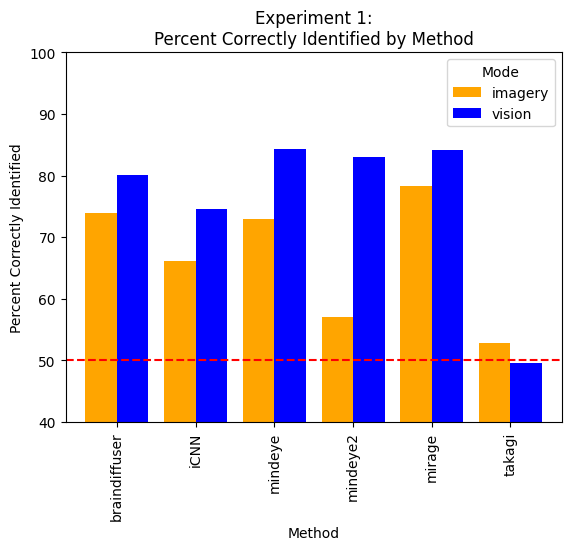

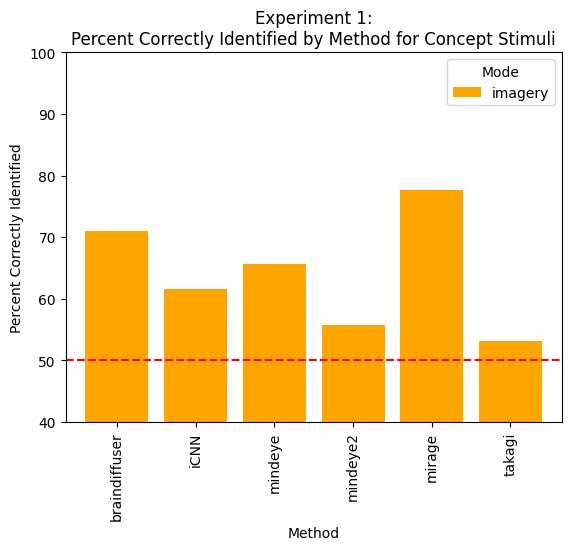

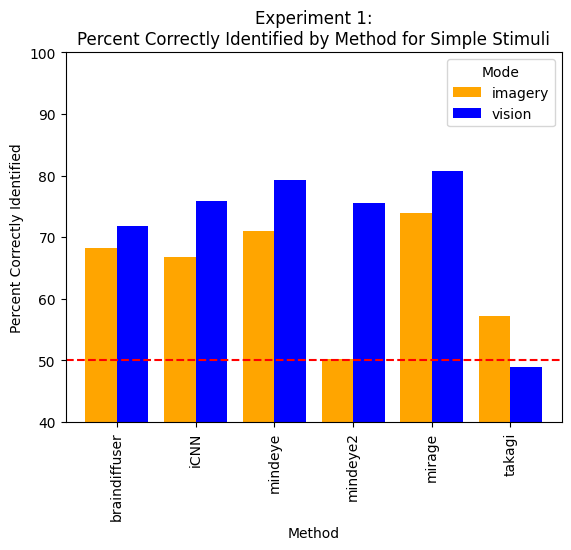

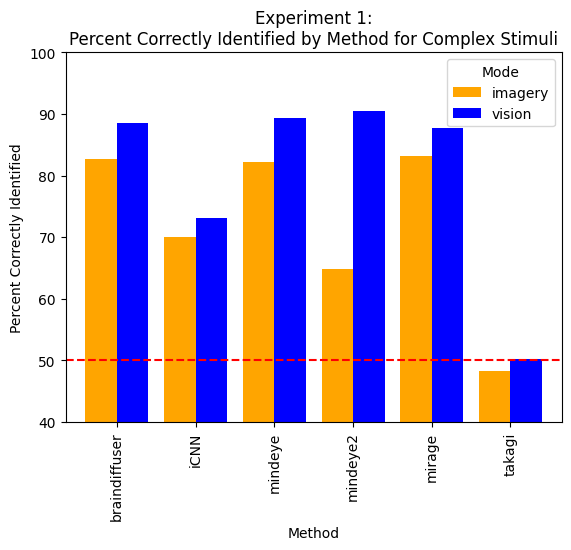

In [163]:
filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')
experiment = 1
df_trial_exp = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == experiment)]
import matplotlib.pyplot as plt

# Calculate the percentage of "picked_target" values by method and mode
percentages = df_trial_exp.groupby(['method', 'mode'])['picked_target'].mean().unstack() * 100

# Plot the bar plot
ax = percentages.plot(kind='bar', color=['orange', 'blue'], width=0.8)
ax.set_ylim(40, 100)  # Set the Y axis to start at 45%
ax.axhline(y=50, color='r', linestyle='--')  # Add a dashed horizontal line at 50%

# Add labels and title
plt.xlabel('Method')
plt.ylabel('Percent Correctly Identified')
plt.title('Experiment 1:\nPercent Correctly Identified by Method')

# Add legend
plt.legend(title='Mode')

# Show the plot
plt.show()

# Iterate over each unique value of the "stimtype" column
for stimtype in df_trial_exp['stimtype'].unique():
    # Filter the dataframe for the current stimtype
    df_stimtype = df_trial_exp[df_trial_exp['stimtype'] == stimtype]
    
    # Calculate the percentage of "picked_target" values by method and mode
    percentages = df_stimtype.groupby(['method', 'mode'])['picked_target'].mean().unstack() * 100
    
    # Plot the bar plot
    ax = percentages.plot(kind='bar', color=['orange', 'blue'], width=0.8)
    ax.set_ylim(40, 100)  # Set the Y axis to start at 45%
    ax.axhline(y=50, color='r', linestyle='--')  # Add a dashed horizontal line at 50%
    
    # Add labels and title
    plt.xlabel('Method')
    plt.ylabel('Percent Correctly Identified')
    plt.title(f'Experiment 1:\nPercent Correctly Identified by Method for {stimtype.capitalize()} Stimuli')
    
    # Add legend
    plt.legend(title='Mode')
    
    # Show the plot
    plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [00:07<00:00, 127.77it/s]


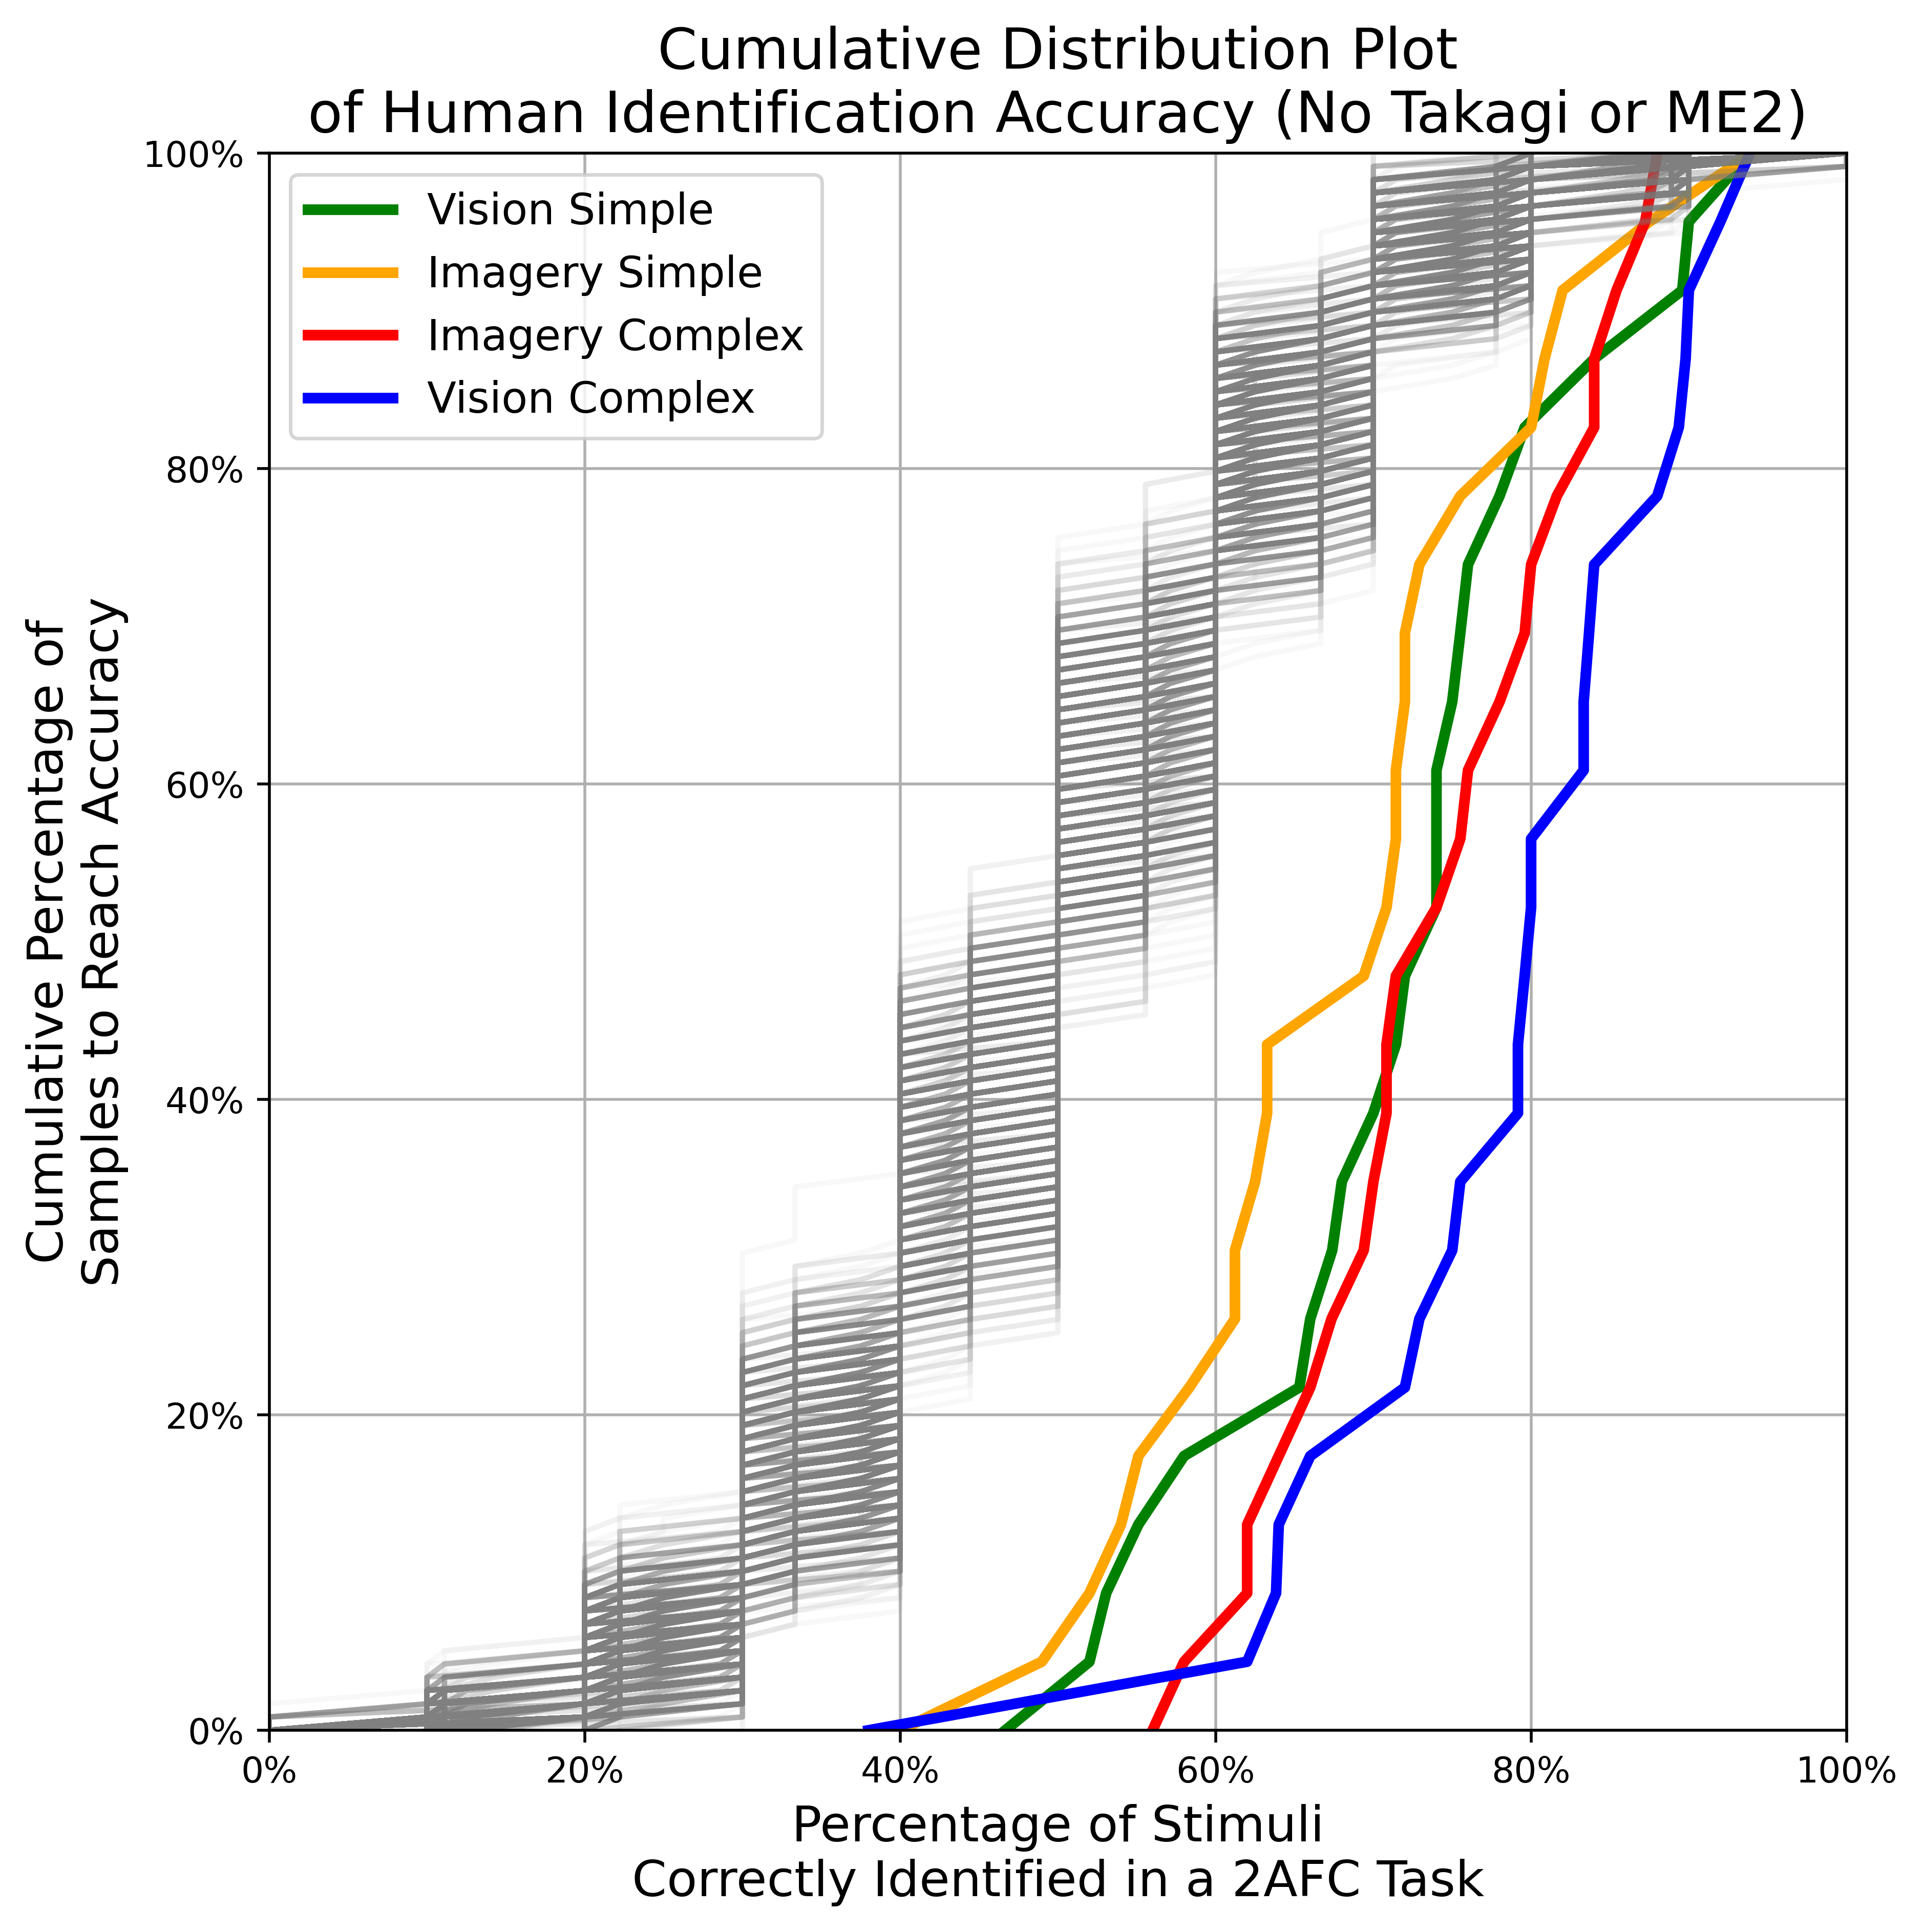

In [176]:

import matplotlib.ticker as mtick
human_df = filtered_df[(filtered_df['experiment'] == 1) & (filtered_df['method'] != "tagaki") & (filtered_df['method'] != "mindeye2")]# 
grouped_data = human_df.groupby(['sample', 'subject', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
grouped_data.rename(columns={'picked_target': 'Accuracy'}, inplace=True)
grouped_data['Accuracy'] *= 100

# Function to calculate cumulative distribution
def cumulative_distribution(data):
    # Sort data
    data_sorted = np.sort(data)
    # Calculate cumulative probability for each value in the sorted array
    p = 100. * np.arange(len(data)) / (len(data) - 1)
    return data_sorted, p

# Separate the data into the four groups
vision_complex = grouped_data[(grouped_data['mode'] == 'vision') & (grouped_data['stimtype'] == 'complex')]['Accuracy']
vision_simple = grouped_data[(grouped_data['mode'] == 'vision') & (grouped_data['stimtype'] == 'simple')]['Accuracy']
imagery_complex = grouped_data[(grouped_data['mode'] == 'imagery') & (grouped_data['stimtype'] == 'complex')]['Accuracy']
imagery_simple = grouped_data[(grouped_data['mode'] == 'imagery') & (grouped_data['stimtype'] == 'simple')]['Accuracy']

# Calculate cumulative distributions for each group using the previously defined function
vision_complex_sorted, p_vision_complex = cumulative_distribution(vision_complex)
vision_simple_sorted, p_vision_simple = cumulative_distribution(vision_simple)
imagery_complex_sorted, p_imagery_complex = cumulative_distribution(imagery_complex)
imagery_simple_sorted, p_imagery_simple = cumulative_distribution(imagery_simple)

# Plotting
fig, ax = plt.subplots(figsize=(8, 8), dpi=500)  # Create a square figure
ax.plot(vision_simple_sorted, p_vision_simple, color='green', label='Vision Simple', linewidth=3)
ax.plot(imagery_simple_sorted, p_imagery_simple, color='orange', label='Imagery Simple', linewidth=3)
ax.plot(imagery_complex_sorted, p_imagery_complex, color='red', label='Imagery Complex', linewidth=3)
ax.plot(vision_complex_sorted, p_vision_complex, color='blue', label='Vision Complex', linewidth=3)

for _ in tqdm(range(1000)):
    # Randomize 'picked_target'
    randomized_df = human_df.copy()
    randomized_df['picked_target'] = np.random.rand(len(randomized_df)) < 0.5

    # Group and calculate new accuracies
    randomized_grouped_data = randomized_df.groupby(['sample', 'subject', 'method', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
    randomized_grouped_data.rename(columns={'picked_target': 'Accuracy'}, inplace=True)
    randomized_grouped_data['Accuracy'] *= 100
    # Separate the data into the four groups
    randomized_vision_complex = randomized_grouped_data[(randomized_grouped_data['mode'] == 'vision') & (randomized_grouped_data['stimtype'] == 'complex')]['Accuracy']
    randomized_vision_simple = randomized_grouped_data[(randomized_grouped_data['mode'] == 'vision') & (randomized_grouped_data['stimtype'] == 'simple')]['Accuracy']
    randomized_imagery_complex = randomized_grouped_data[(randomized_grouped_data['mode'] == 'imagery') & (randomized_grouped_data['stimtype'] == 'complex')]['Accuracy']
    randomized_imagery_simple = randomized_grouped_data[(randomized_grouped_data['mode'] == 'imagery') & (randomized_grouped_data['stimtype'] == 'simple')]['Accuracy']

    # Calculate cumulative distributions for each randomized group
    r_vision_complex_sorted, r_p_vision_complex = cumulative_distribution(randomized_vision_complex)
    r_vision_simple_sorted, r_p_vision_simple = cumulative_distribution(randomized_vision_simple)
    r_imagery_complex_sorted, r_p_imagery_complex = cumulative_distribution(randomized_imagery_complex)
    r_imagery_simple_sorted, r_p_imagery_simple = cumulative_distribution(randomized_imagery_simple)

    # Plot the randomized data
    ax.plot(r_vision_simple_sorted, r_p_vision_simple, color="gray", alpha=0.05)
    ax.plot(r_vision_complex_sorted, r_p_vision_complex, color="gray", alpha=0.05)
    ax.plot(r_imagery_simple_sorted, r_p_imagery_simple, color="gray", alpha=0.05)
    ax.plot(r_imagery_complex_sorted, r_p_imagery_complex, color="gray", alpha=0.05)

# Adding labels and title
ax.set_xlabel(f'Percentage of Stimuli\nCorrectly Identified in a 2AFC Task', fontsize=14)
ax.set_ylabel('Cumulative Percentage of\nSamples to Reach Accuracy', fontsize=14)
ax.set_title(f'Cumulative Distribution Plot\nof Human Identification Accuracy (No Takagi or ME2)', fontsize=16)
ax.legend(loc='upper left', fontsize=12)
ax.grid(True)
# plt.tight_layout()
# Format x-axis ticks as percentages
ax.xaxis.set_major_formatter(mtick.PercentFormatter())

# Format y-axis ticks as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
# Set the x-axis limit to end at 100%
ax.set_xlim(0, 100)

# Set the y-axis limit to end at 100%
ax.set_ylim(0, 100)

# Ensure the aspect ratio of the plot is equal
ax.set_aspect('equal', adjustable='box')

plt.show()


In [94]:

# Iterate over each experiment
experiment = 1
for mode in ["vision", "imagery"]:
    
    print(f"Mode: {mode}")
    for stimtype in ["simple", "complex", "concept"]:
        print(f"Stimtype: {stimtype}")
        # Filter the data for the current method, mode, and experiment
        df_trial_exp1 = df_trial_exp[(df_trial_exp['method'] != "takagi") & (df_trial_exp['method'] != "mindeye2") & (df_trial_exp['experiment'] == experiment) & (df_trial_exp['mode'] == mode) & (df_trial_exp['stimtype'] == stimtype)]
        
        if len(df_trial_exp1) == 0:
                print("No trials for this combination")
                continue
        # Perform a binomial test
        # The null hypothesis is that the probability of success is 0.5 (chance level)
        p_value = binomtest(df_trial_exp1['picked_target'].sum(), n=len(df_trial_exp1['picked_target']), p=0.5, alternative='two-sided').pvalue

        print("Number of experiment trials:", len(df_trial_exp1))
        print("Success rate: ", len(df_trial_exp1[df_trial_exp1["picked_target"]]) / len(df_trial_exp1))
        print(f'P-value: {p_value}')
        
        print("--------------------")
        print()


Mode: vision
Stimtype: simple
Number of experiment trials: 941
Success rate:  0.769394261424017
P-value: 2.2939694203315062e-64
--------------------

Stimtype: complex
Number of experiment trials: 938
Success rate:  0.8464818763326226
P-value: 1.752884474020269e-109
--------------------

Stimtype: concept
No trials for this combination
Mode: imagery
Stimtype: simple
Number of experiment trials: 943
Success rate:  0.6998939554612937
P-value: 2.1556147191267082e-35
--------------------

Stimtype: complex
Number of experiment trials: 949
Success rate:  0.7839831401475237
P-value: 2.1206237627706288e-72
--------------------

Stimtype: concept
Number of experiment trials: 944
Success rate:  0.6896186440677966
P-value: 5.951434073249629e-32
--------------------



In [164]:
# Load filtered responses
experiment = 2
df_trial_exp = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == experiment)]
print(len(df_trial_exp))
# # Iterate over each method
# for method in df_trial_exp['method'].unique():
#         print(f"Method: {method}")
print("--------------------")
for stimtype in ["simple", "complex", "concept"]:
        print(f"Stimtype: {stimtype}")
        # Filter the data for the current method, mode, and experiment
        df_trial_exp_stim = df_trial_exp[(df_trial_exp['stimtype'] == stimtype)]
        # Perform a binomial test
        # The null hypothesis is that the probability of success is 0.5 (chance level)
        if len(df_trial_exp_stim) == 0:
                print("No trials for this combination")
                continue
        p_value = binomtest(df_trial_exp_stim['picked_target'].sum(), n=len(df_trial_exp_stim['picked_target']), p=0.5, alternative='two-sided').pvalue

        print("Number of experiment trials:", len(df_trial_exp_stim))
        print("Success rate: ", len(df_trial_exp_stim[df_trial_exp_stim["picked_target"]]) / len(df_trial_exp_stim))
        print(f'P-value: {p_value}')

        print("--------------------")
        print()


2828
--------------------
Stimtype: simple
Number of experiment trials: 1417
Success rate:  0.6153846153846154
P-value: 3.3564290270621505e-18
--------------------

Stimtype: complex
Number of experiment trials: 1411
Success rate:  0.6746987951807228
P-value: 5.438223009545327e-40
--------------------

Stimtype: concept
No trials for this combination


Method: mirage, Average Vision Similarity: 0.305, Average Vision Confidence: 0.215, Average Imagery Similarity: 0.207, Average Imagery Confidence: 0.217
Method: mindeye2, Average Vision Similarity: 0.336, Average Vision Confidence: 0.196, Average Imagery Similarity: 0.115, Average Imagery Confidence: 0.211
Method: takagi, Average Vision Similarity: 0.142, Average Vision Confidence: 0.187, Average Imagery Similarity: 0.141, Average Imagery Confidence: 0.183
Method: braindiffuser, Average Vision Similarity: 0.233, Average Vision Confidence: 0.217, Average Imagery Similarity: 0.158, Average Imagery Confidence: 0.223
Method: iCNN, Average Vision Similarity: 0.215, Average Vision Confidence: 0.233, Average Imagery Similarity: 0.111, Average Imagery Confidence: 0.223
Method: mindeye, Average Vision Similarity: 0.306, Average Vision Confidence: 0.220, Average Imagery Similarity: 0.181, Average Imagery Confidence: 0.200


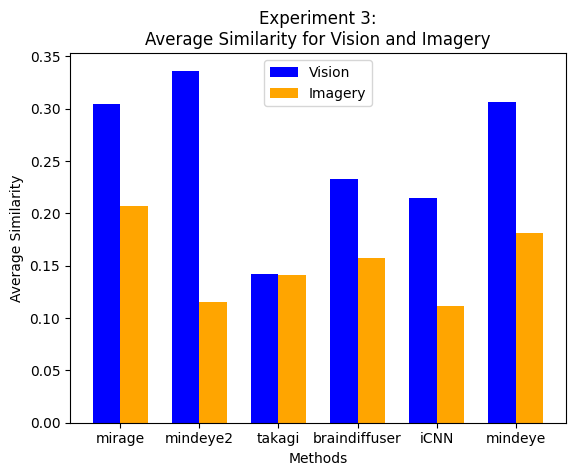

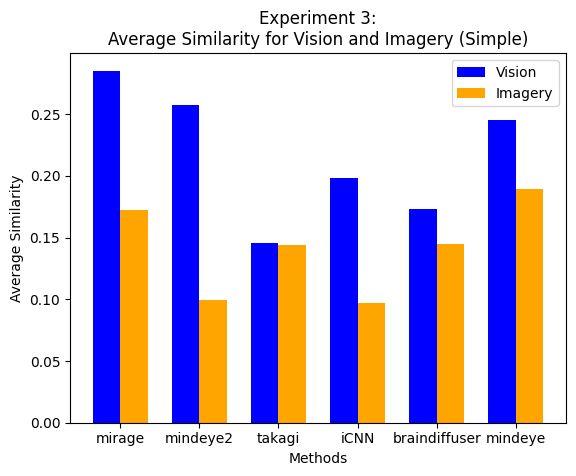

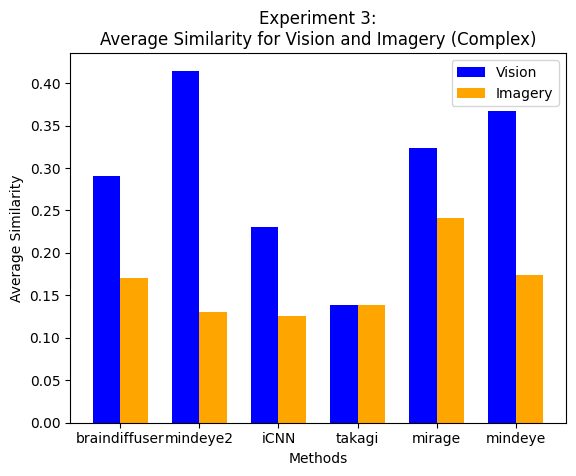

In [167]:
import matplotlib.pyplot as plt
df_trial_exp3 = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == 3)]
# Calculate the average similarity and confidence for each method and stimtype
averages = []
for method in df_trial_exp3['method'].unique():
    # for stimtype in df_trial_exp3['stimtype'].unique():
    category_df = df_trial_exp3[(df_trial_exp3["method"] == method)]
    avg_vision_similarity = category_df['target_similarity'].mean()
    avg_imagery_similarity = category_df['distractor_similarity'].mean()
    avg_vision_confidence = category_df['target_confidence'].mean()
    avg_imagery_confidence = category_df['distractor_confidence'].mean()
    print(f"Method: {method}, Average Vision Similarity: {avg_vision_similarity:.3f}, Average Vision Confidence: {avg_vision_confidence:.3f}, Average Imagery Similarity: {avg_imagery_similarity:.3f}, Average Imagery Confidence: {avg_imagery_confidence:.3f}")
    averages.append((method, stimtype, avg_vision_similarity, avg_imagery_similarity))

# Create a list of methods and their corresponding average similarity values for vision and imagery
methods = []
vision_similarities = []
imagery_similarities = []

for method, _, avg_vision_similarity, avg_imagery_similarity in averages:
    methods.append(method)
    vision_similarities.append(avg_vision_similarity)
    imagery_similarities.append(avg_imagery_similarity)

# Set the width of the bars
bar_width = 0.35

# Set the positions of the bars on the X-axis
r1 = np.arange(len(methods))
r2 = [x + bar_width for x in r1]

# Plot the bars
plt.bar(r1, vision_similarities, color='blue', width=bar_width, label='Vision')
plt.bar(r2, imagery_similarities, color='orange', width=bar_width, label='Imagery')

# Add labels and title
plt.xlabel('Methods')
plt.ylabel('Average Similarity')
plt.title('Experiment 3:\nAverage Similarity for Vision and Imagery')
plt.xticks([r + bar_width/2 for r in range(len(methods))], methods)

# Add legend
plt.legend()

# Show the plot
plt.show()

# Iterate over each unique value of the "stimtype" column
for stimtype in df_trial_exp3['stimtype'].unique():
    # Filter the dataframe for the current stimtype
    df_stimtype = df_trial_exp3[df_trial_exp3['stimtype'] == stimtype]
    
    # Calculate the average similarity and confidence for each method
    averages = []
    for method in df_stimtype['method'].unique():
        category_df = df_stimtype[df_stimtype["method"] == method]
        avg_vision_similarity = category_df['target_similarity'].mean()
        avg_imagery_similarity = category_df['distractor_similarity'].mean()
        avg_vision_confidence = category_df['target_confidence'].mean()
        avg_imagery_confidence = category_df['distractor_confidence'].mean()
        averages.append((method, stimtype, avg_vision_similarity, avg_imagery_similarity))
    
    # Create a list of methods and their corresponding average similarity values for vision and imagery
    methods = []
    vision_similarities = []
    imagery_similarities = []

    for method, _, avg_vision_similarity, avg_imagery_similarity in averages:
        methods.append(method)
        vision_similarities.append(avg_vision_similarity)
        imagery_similarities.append(avg_imagery_similarity)

    # Set the positions of the bars on the X-axis
    r1 = np.arange(len(methods))
    r2 = [x + bar_width for x in r1]

    # Plot the bars
    plt.bar(r1, vision_similarities, color='blue', width=bar_width, label='Vision')
    plt.bar(r2, imagery_similarities, color='orange', width=bar_width, label='Imagery')

    # Add labels and title
    plt.xlabel('Methods')
    plt.ylabel('Average Similarity')
    plt.title(f'Experiment 3:\nAverage Similarity for Vision and Imagery ({stimtype.capitalize()})')
    plt.xticks([r + bar_width/2 for r in range(len(methods))], methods)

    # Add legend
    plt.legend()

    # Show the plot
    plt.show()


/tmp/ipykernel_389171/1381747154.py:10: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df = human_df.groupby(['method', 'sample']).mean().reset_index()


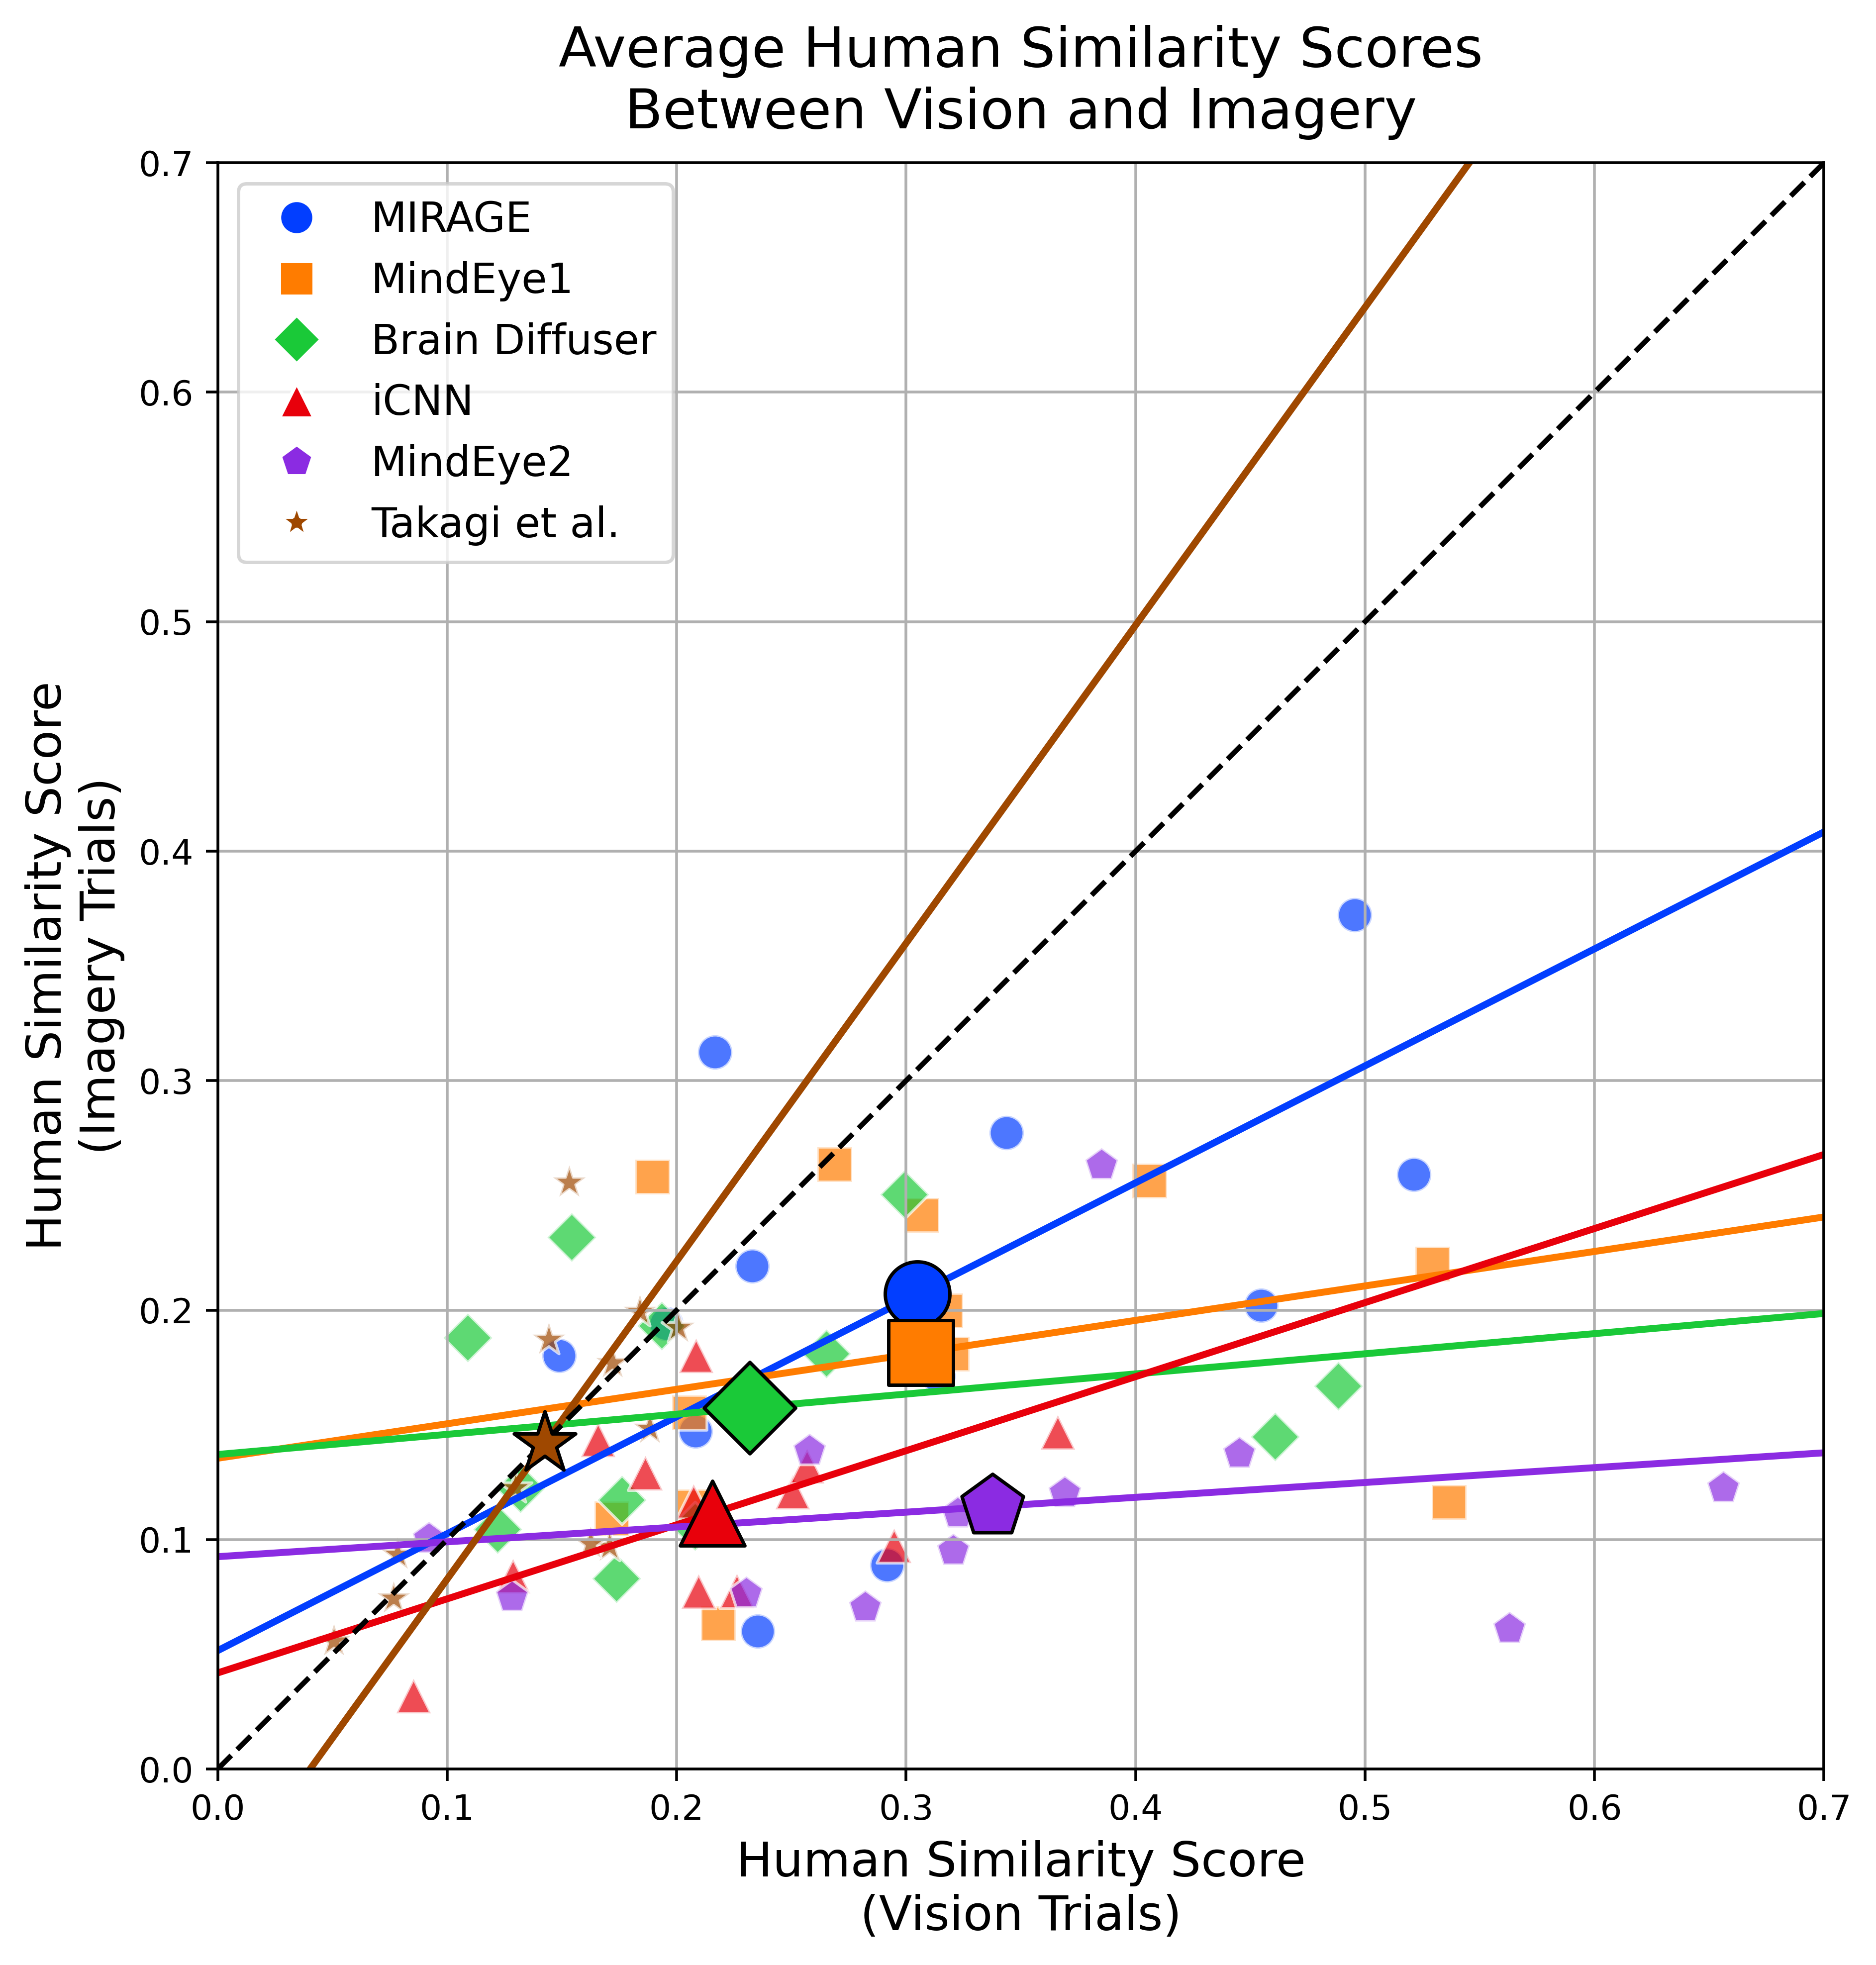

In [169]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == 3)]
# Grouping and averaging
grouped_df = human_df.groupby(['method', 'sample']).mean().reset_index()

# Define a clear mapping for method display names in the legend
method_display_names = {
    "mirage" :  "MIRAGE",
    "mindeye": "MindEye1",
    "braindiffuser": "Brain Diffuser",
    "iCNN" : "iCNN",
    "mindeye2": "MindEye2",
    "takagi" : "Takagi et al."
}

# Prepare the plot
fig, ax = plt.subplots(figsize=(8, 8), dpi=500)  # Create a square figure
bright_palette = sns.color_palette('bright', len(method_display_names))
markers = ['o', 's', 'D', '^', 'p', '*']

# First, plot the scatter and PCA lines for each method
for i, (method_code, method_display) in enumerate(method_display_names.items()):
    method_data = grouped_df[grouped_df['method'] == method_code]
    # Scatter plot for individual points
    sns.scatterplot(data=method_data, x='target_similarity', y='distractor_similarity', color=bright_palette[i], 
                    label=method_display, s=100, marker=markers[i], alpha=0.7, ax=ax)

    # PCA for best fit line
    pca = PCA(n_components=2)
    points = method_data[['target_similarity', 'distractor_similarity']].dropna()
    pca.fit(points)
    center = pca.mean_
    pc1 = pca.components_[0]
    line_x = np.linspace(points['target_similarity'].min() - 0.5, points['target_similarity'].max() + 0.5, 2)
    line_y = (pc1[1] / pc1[0]) * (line_x - center[0]) + center[1]
    ax.plot(line_x, line_y, color=bright_palette[i], linewidth=2)

# Then, plot the large dots for the mean of each method, ensuring they appear on top
for i, (method_code, method_display) in enumerate(method_display_names.items()):
    method_data = grouped_df[grouped_df['method'] == method_code]
    avg_target_similarity = method_data['target_similarity'].mean()
    avg_distractor_similarity = method_data['distractor_similarity'].mean()
    ax.scatter(avg_target_similarity, avg_distractor_similarity, color=bright_palette[i], marker=markers[i], s=350, edgecolors='black', zorder=5)

ax.set_title('Average Human Similarity Scores\nBetween Vision and Imagery', pad=10, fontsize=16)
ax.set_xlabel('Human Similarity Score\n(Vision Trials)', fontsize=14)
ax.set_ylabel('Human Similarity Score\n(Imagery Trials)', fontsize=14)
plt.tight_layout()
ax.grid(True)
ax.set_xlim(0, 0.7)
ax.set_ylim(0, 0.7)
ax.set_aspect('equal', adjustable='box')
ax.plot([0, 0.7], [0, 0.7], 'k--')  # Line at unity

# Adjusting legend to make sure it represents the latest plotted elements correctly
handles, labels = ax.get_legend_handles_labels()
# Ensuring that new handles created for the legend represent the latest plot elements with the correct zorder
new_handles = [plt.Line2D([], [], marker=marker, color='w', markerfacecolor=bright_palette[i], markersize=10, alpha=1) for i, marker in enumerate(markers[:len(method_display_names)])]
ax.legend(new_handles, labels[:len(method_display_names)], bbox_to_anchor=(0, 1), loc='upper left', fontsize=12)

plt.show()


Method: mindeye, Average Method Similarity: 0.234, Average Method Confidence: 0.188, Average Distractor Similarity: 0.154, Average Distractor Confidence: 0.158
Method: braindiffuser, Average Method Similarity: 0.298, Average Method Confidence: 0.208, Average Distractor Similarity: 0.108, Average Distractor Confidence: 0.139
Method: mirage, Average Method Similarity: 0.336, Average Method Confidence: 0.196, Average Distractor Similarity: 0.146, Average Distractor Confidence: 0.183
Method: iCNN, Average Method Similarity: 0.099, Average Method Confidence: 0.205, Average Distractor Similarity: 0.204, Average Distractor Confidence: 0.181
Method: mindeye2, Average Method Similarity: 0.143, Average Method Confidence: 0.173, Average Distractor Similarity: 0.098, Average Distractor Confidence: 0.140


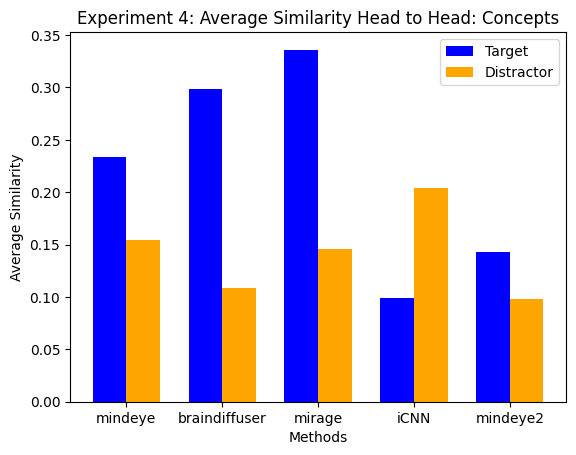

In [170]:
import matplotlib.pyplot as plt
df_trial_exp3 = filtered_df[(filtered_df['catch_trial'].isnull()) & (filtered_df['experiment'] == 4)]
# Calculate the average similarity and confidence for each method and stimtype
averages = []
for method in df_trial_exp3['stim2_method'].unique():
    # for stimtype in df_trial_exp3['stimtype'].unique():
    category_df = df_trial_exp3[(df_trial_exp3["stim2_method"] == method)]
    avg_target_similarity = category_df['target_similarity'].mean()
    avg_distractor_similarity = category_df['distractor_similarity'].mean()
    avg_target_confidence = category_df['target_confidence'].mean()
    avg_distractor_confidence = category_df['distractor_confidence'].mean()
    print(f"Method: {method}, Average Method Similarity: {avg_target_similarity:.3f}, Average Method Confidence: {avg_target_confidence:.3f}, Average Distractor Similarity: {avg_distractor_similarity:.3f}, Average Distractor Confidence: {avg_distractor_confidence:.3f}")
    averages.append((method, stimtype, avg_target_similarity, avg_distractor_similarity))

# Create a list of methods and their corresponding average similarity values for vision and imagery
methods = []
target_similarities = []
distractor_similarities = []

for method, _, avg_target_similarity, avg_distractor_similarity in averages:
    methods.append(method)
    target_similarities.append(avg_target_similarity)
    distractor_similarities.append(avg_distractor_similarity)

# Set the width of the bars
bar_width = 0.35

# Set the positions of the bars on the X-axis
r1 = np.arange(len(methods))
r2 = [x + bar_width for x in r1]

# Plot the bars
plt.bar(r1, target_similarities, color='blue', width=bar_width, label='Target')
plt.bar(r2, distractor_similarities, color='orange', width=bar_width, label='Distractor')

# Add labels and title
plt.xlabel('Methods')
plt.ylabel('Average Similarity')
plt.title('Experiment 4: Average Similarity Head to Head: Concepts')
plt.xticks([r + bar_width/2 for r in range(len(methods))], methods)

# Add legend
plt.legend()

# Show the plot
plt.show()



In [58]:
filtered_df.head()

,pID,experiment,stim1,stim2,stim3,sample,subject,target_on_left,method,catch_trial,rep,mode,stimtype,picked_left,participant,response_time,stim2_similarity,stim2_confidence,stim3_similarity,stim3_confidence,target_similarity,target_confidence,distractor_similarity,distractor_confidence,picked_target,stim2_method,stim3_method,picked_method,similarity_diff
1,1,1,0_ground_truth,0_9_imagery_subject7_mirage,0_9_imagery_subject7_mindeye,0,7,NaN,mirage_vs_mindeye,NaN,9,imagery,simple,False,certain-cowbird,10.522,0.158792,0.444340,0.879062,0.667132,0.158792,0.444340,0.879062,0.667132,False,mirage_vs_mindeye,mirage_vs_mindeye,None,-0.720270
2,1,1,5_ground_truth,5_6_vision_subject7_iCNN,5_6_vision_subject7_mindeye,5,7,NaN,iCNN_vs_mindeye,NaN,6,vision,simple,False,certain-cowbird,3.126,0.092832,0.319586,0.699290,0.740620,0.092832,0.319586,0.699290,0.740620,False,iCNN_vs_mindeye,iCNN_vs_mindeye,None,-0.606457
3,1,1,3_ground_truth,3_9_imagery_subject5_mirage,3_9_imagery_subject5_mindeye,3,5,NaN,mirage_vs_mindeye,NaN,9,imagery,simple,False,certain-cowbird,2.868,0.122780,0.574545,0.897142,0.464631,0.122780,0.574545,0.897142,0.464631,False,mirage_vs_mindeye,mirage_vs_mindeye,None,-0.774362
4,1,1,4_ground_truth,4_9_imagery_subject5_mirage,4_9_imagery_subject5_mindeye,4,5,NaN,mirage_vs_mindeye,NaN,9,imagery,simple,False,certain-cowbird,3.168,0.006767,0.883747,0.435175,0.455663,0.006767,0.883747,0.435175,0.455663,False,mirage_vs_mindeye,mirage_vs_mindeye,None,-0.428408
6,1,1,3_ground_truth,3_3_imagery_subject2_iCNN,3_3_imagery_subject2_mindeye2,3,2,NaN,iCNN_vs_mindeye2,NaN,3,imagery,simple,False,certain-cowbird,2.090,0.166518,0.282751,0.612749,0.729938,0.166518,0.282751,0.612749,0.729938,False,iCNN_vs_mindeye2,iCNN_vs_mindeye2,None,-0.446231


/tmp/ipykernel_4186311/2147438201.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  experiment_4_df['similarity_diff'] = experiment_4_df['stim2_similarity'] - experiment_4_df['stim3_similarity']


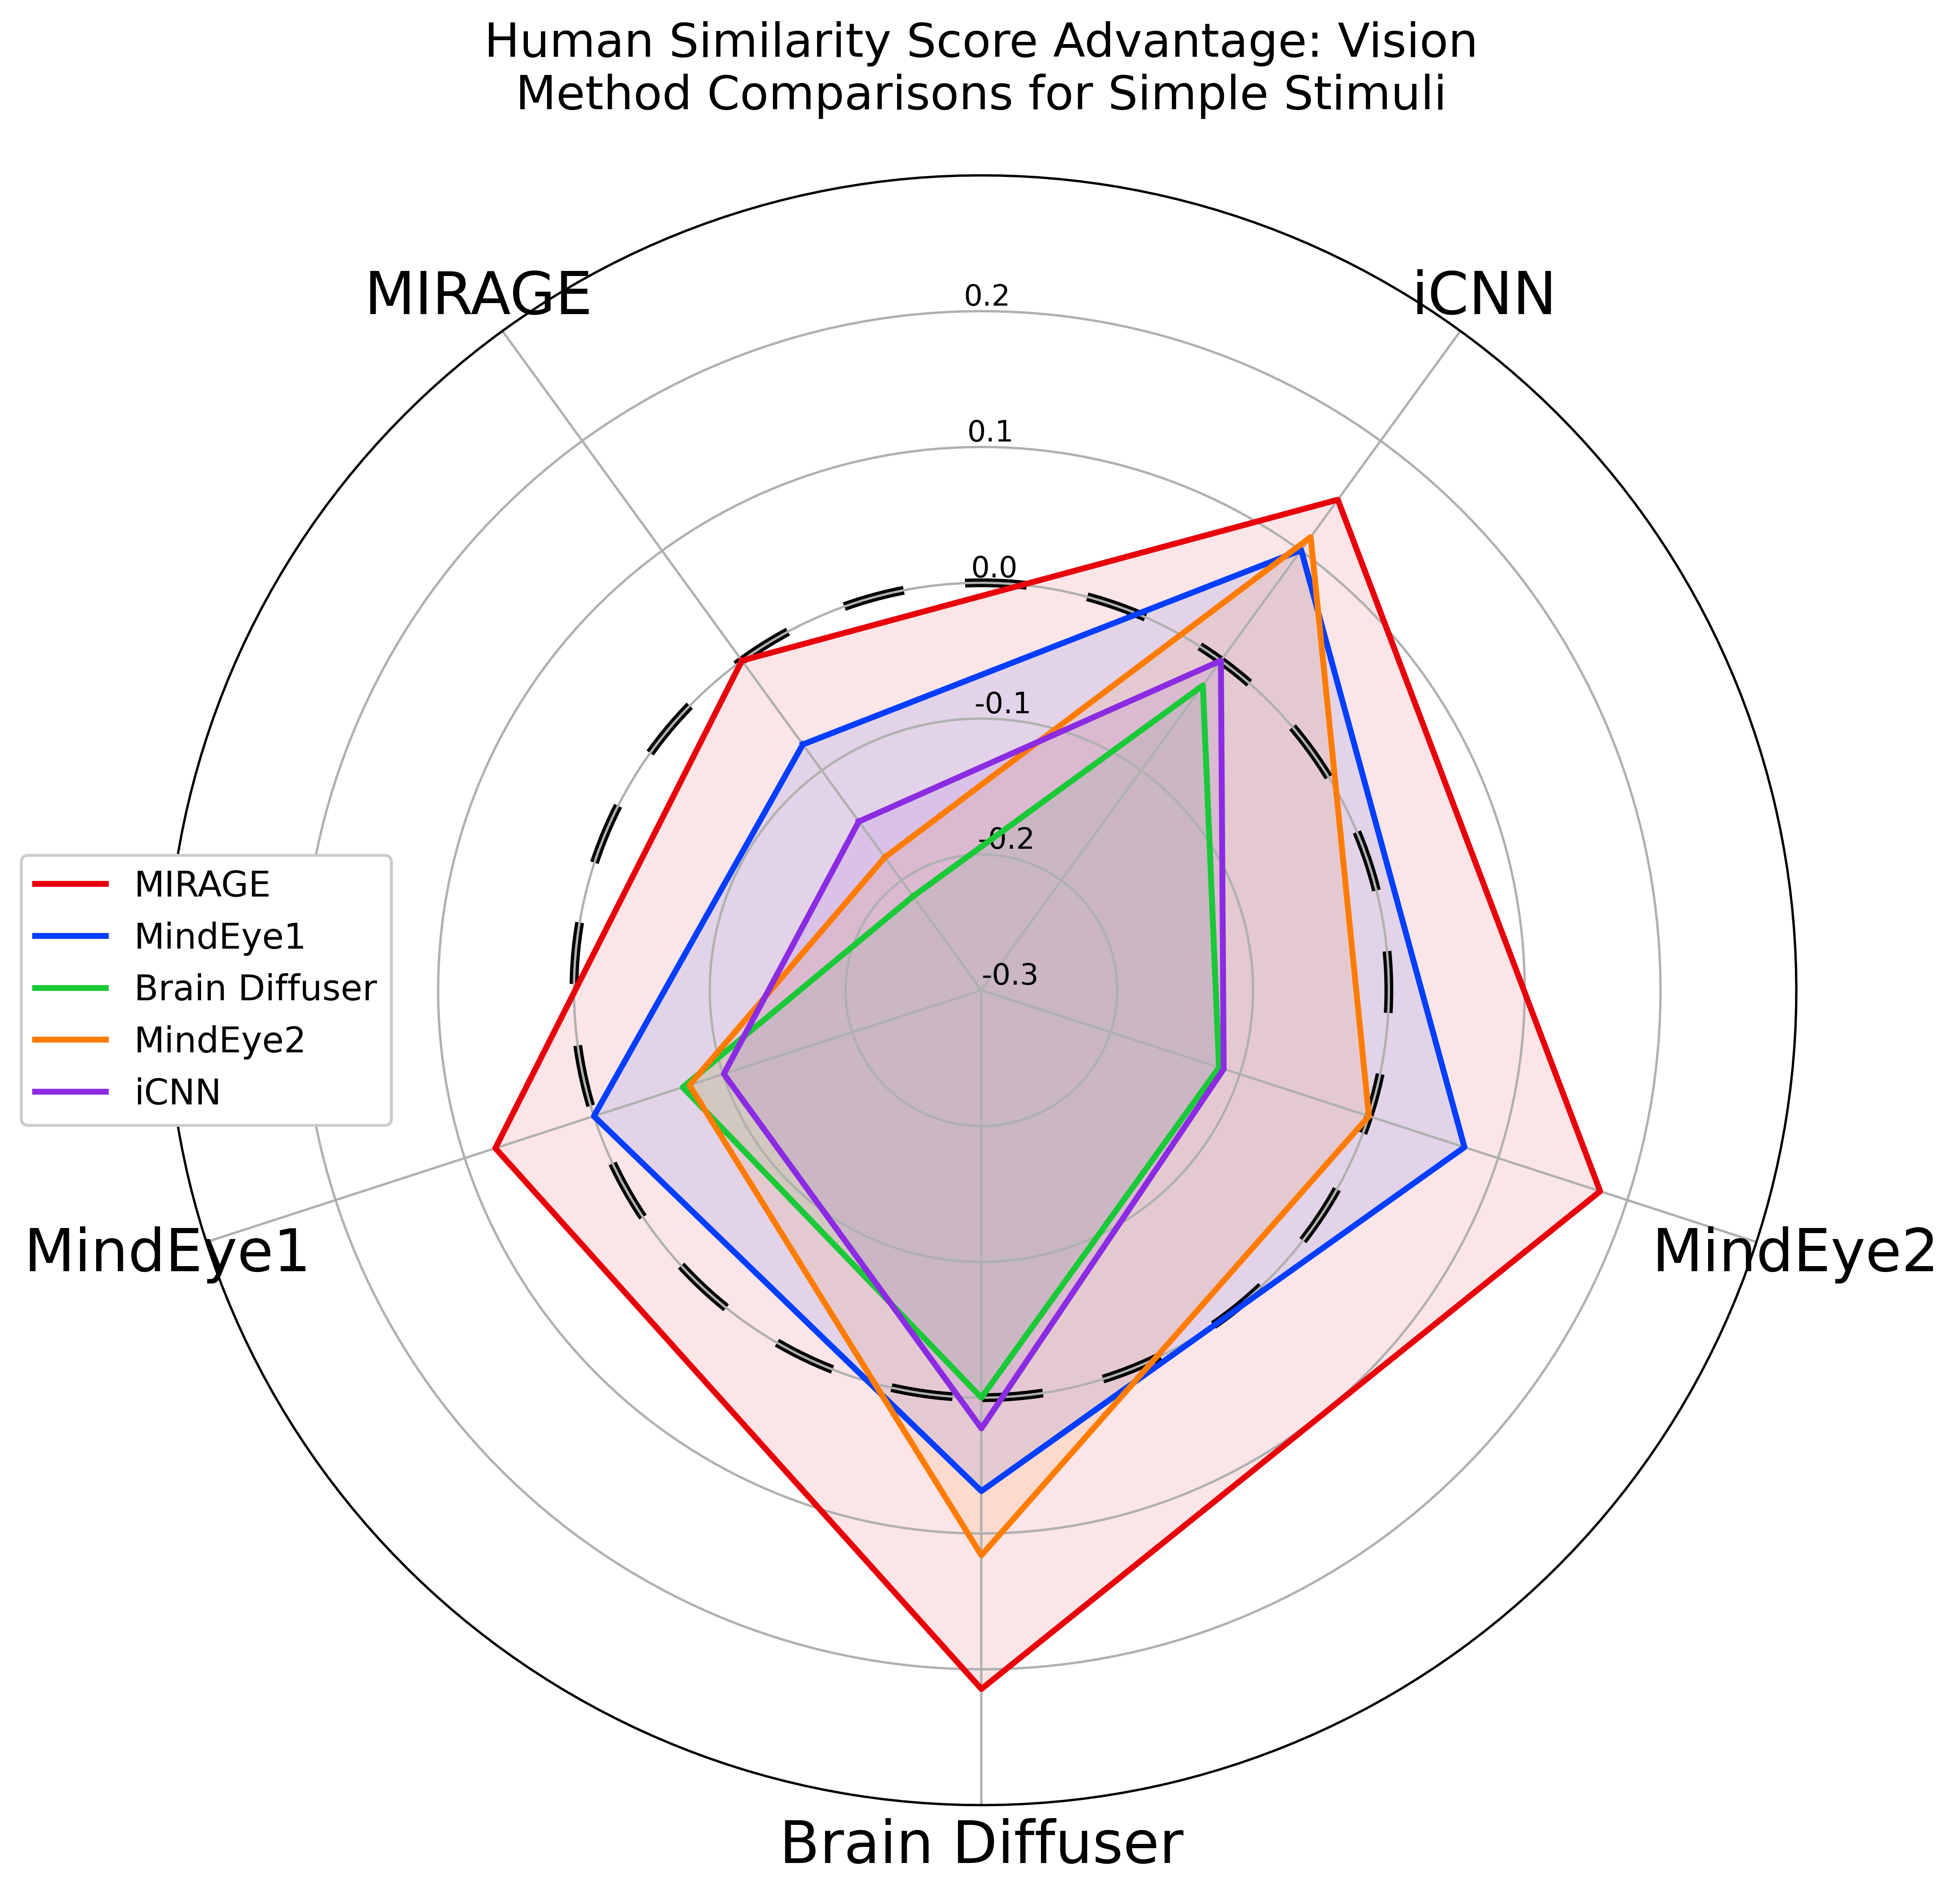

In [71]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


experiment_4_df = filtered_df[filtered_df['mode'] == 'vision']

# Calculate the difference in similarity scores
experiment_4_df['similarity_diff'] = experiment_4_df['stim2_similarity'] - experiment_4_df['stim3_similarity']

# Create a pivot table to organize the data for the star plot
method_names = {
    'mirage': 'MIRAGE',
    'mindeye': 'MindEye1',
    'braindiffuser': 'Brain Diffuser',
    'mindeye2': 'MindEye2',
    'iCNN': 'iCNN',
    # 'takagi': 'Takagi et al.'
}
method_pairs = [(m1, m2) for m1 in method_names.keys() for m2 in method_names.keys()]

# Initialize an empty DataFrame to store the average similarity differences for each method pair
pivot_data = pd.DataFrame(index=method_names.keys(), columns=method_names.keys(), data=0)  # Start with 0 for diagonal

# Calculate the average similarity difference for each head-to-head matchup
for method1, method2 in method_pairs:
    if method1 != method2:
        subset = experiment_4_df[(experiment_4_df['stim2_method'] == method1) & (experiment_4_df['stim3_method'] == method2)]
        if not subset.empty:
            avg_diff = subset['similarity_diff'].mean()
            pivot_data.loc[method1, method2] = avg_diff
            pivot_data.loc[method2, method1] = -avg_diff



# Create a list of angles for the radar chart
N = len(method_names.keys())
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # Complete the loop

# Initialize the radar chart
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True), dpi=500)

# ----- Add Rotation Offset Here -----
# Calculate the rotation angle in radians
rotation_degrees = 126
rotation_radians = np.deg2rad(rotation_degrees)

# Apply the rotation to the polar plot
ax.set_theta_offset(rotation_radians)
# -----------------------------------

# Define colors using a bright palette from Seaborn
bright_palette = sns.color_palette('bright', len(method_names.keys()))
# Change colors to my liking
bright_palette[0], bright_palette[1], bright_palette[3] = bright_palette[3], bright_palette[0], bright_palette[1]
colors = {method: bright_palette[i] for i, method in enumerate(method_names.keys())}

# Plot each method as a line on the radar chart
for method in method_names.keys():
    values = pivot_data.loc[method].tolist()
    values += values[:1]  # Complete the loop
    # if method == 'mindeye':
    #     values = [x - 0.02 for x in values]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=method_names[method], color=colors[method])
    ax.fill(angles, values, color=colors[method], alpha=0.1)

# Add labels for methods
plt.xticks(angles[:-1], [method_names[method] for method in method_names.keys()], color='black', size=20)
ax.set_rlabel_position(-34.5)
plt.yticks([-0.3, -0.2, -0.1, 0, 0.1, 0.2], ["-0.3", "-0.2", "-0.1", "0.0", "0.1", "0.2"], color="black", size=10)
plt.ylim(-0.3, 0.3)

# Bold the circular y-axis line at 0 to indicate equal similarity
circle = plt.Circle((0, 0), 0.3, transform=ax.transData._b, color='black', fill=False, linewidth=3., linestyle=(0, (7, 7)))
ax.add_artist(circle)

# Add a title and legend
plt.title('Human Similarity Score Advantage: Vision\nMethod Comparisons for Simple Stimuli', size=20, color='black', y=1.03, fontsize=16)
plt.legend(loc='center left', bbox_to_anchor=(-0.1, 0.5), fontsize=12, framealpha=1)

plt.show()